# SVM: Does More Hyperparameter Tuning Help?
Owner: Anupama Singh

A "setting" is one combination of SVM options (for example "RBF kernel, C = 1, gamma = 0.01"). The SVM notebook
originally tuned over 7 settings. This notebook checks whether smaller or larger searches do better. Ten ways of tuning
are compared, from 2 settings to 150:

| Variant | Settings searched | Chosen by |
|---|---|---|
| **A. Tiny grid** | 2: linear C=0.1, RBF C=1 | ROC AUC |
| **B. Small grid** | 4: linear C=0.1 or 1, RBF C=1 or 3 | ROC AUC |
| **C. Original grid** | 7: linear C=0.01/0.1/1, RBF C=0.1/0.3/1/3 (gamma left at its default) | ROC AUC |
| **D. Small RBF grid** | 9: RBF only, C=1/3/10 × gamma=scale/0.01/0.03 | ROC AUC |
| **E. Medium grid (now used)** | 24: linear with 6 values of C, RBF with 6 values of C × 3 values of gamma | ROC AUC |
| **F. Medium + class weights** | 48: the same 24, with and without balanced class weights | ROC AUC |
| **G. Wider grid** | 102: linear, RBF, polynomial, sigmoid kernels; C from 0.001 to 30; 5 gamma values; class weights | ROC AUC |
| **H. Random search** | 150 random settings: 4 kernels, C up to 100, gamma 0.0001 to 1, class weights, 3 feature-scaling methods | ROC AUC |
| **I. Random search** | same 150 settings | PR-AUC (the team's main metric) |
| **J. Random search + cutoff** | same 150 settings, plus the score cutoff for "high growth" | PR-AUC, cutoff chosen for best accuracy |

Every variant uses the same 706 students and the same 5 outer folds as the other notebooks. Settings (and the cutoff)
are always chosen with an inner 4-fold cross-validation on the **training schools only**; the test fold is never used.

## 1. Setup and data

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score

warnings.filterwarnings("ignore")
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL
# Outputs go to their own folder: results/svm_tuning/
RESULTS = (Path("../results") if Path("../results").exists() else Path("results")) / "svm_tuning"
RESULTS.mkdir(parents=True, exist_ok=True)

FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS", "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}
SPLITS = {"school": "SchlID", "student": "StuID"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
data = df[df["RMwidRS_target"].notna()].dropna(subset=FEATURES).reset_index(drop=True)
X = data[FEATURES]
print(f"Students: {len(data)} | Schools: {data['SchlID'].nunique()}")

Students: 706 | Schools: 42


## 2. The search spaces
Each setting is (kernel, C, gamma, polynomial degree, class weight, feature scaling).
- **C**: how hard the SVM tries to classify every training student correctly (large C = less regularization).
- **gamma**: how curved the RBF boundary can be (large gamma = more curved).
- **class weight "balanced"**: gives the smaller class more weight.
- **Scaling**: standard (mean 0, sd 1), robust (median and interquartile range), or quantile (rank-based).

In [2]:
SCALERS = {"standard": StandardScaler, "robust": RobustScaler,
           "quantile": lambda: QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0)}

TINY = [("linear", 0.1, "scale", 3, None, "standard"), ("rbf", 1, "scale", 3, None, "standard")]
SMALL = [("linear", c, "scale", 3, None, "standard") for c in [0.1, 1]] + \
        [("rbf", c, "scale", 3, None, "standard") for c in [1, 3]]
ORIGINAL = [("linear", c, "scale", 3, None, "standard") for c in [0.01, 0.1, 1]] + \
           [("rbf", c, "scale", 3, None, "standard") for c in [0.1, 0.3, 1, 3]]
SMALL_RBF = [("rbf", c, g, 3, None, "standard") for c in [1, 3, 10] for g in ["scale", 0.01, 0.03]]
MEDIUM = [("linear", c, "scale", 3, None, "standard") for c in [0.01, 0.03, 0.1, 0.3, 1, 3]] + \
         [("rbf", c, g, 3, None, "standard") for c in [0.1, 0.3, 1, 3, 10, 30] for g in ["scale", 0.01, 0.03]]
MEDIUM_CW = MEDIUM + [(k, c, g, d, "balanced", sc) for k, c, g, d, _, sc in MEDIUM]

WIDER = []
for cw in [None, "balanced"]:
    WIDER += [("linear", c, "scale", 3, cw, "standard") for c in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]]
    WIDER += [("rbf", c, g, 3, cw, "standard") for c in [0.1, 0.3, 1, 3, 10, 30]
              for g in ["scale", 0.003, 0.01, 0.03, 0.1]]
    WIDER += [("poly", c, "scale", d, cw, "standard") for c in [0.01, 0.1, 1, 10] for d in [2, 3]]
    WIDER += [("sigmoid", c, g, 3, cw, "standard") for c in [0.01, 0.1, 1] for g in ["scale", 0.01]]

rng = np.random.default_rng(0)
RANDOM = []
for _ in range(150):
    k = rng.choice(["rbf", "rbf", "rbf", "linear", "poly", "sigmoid"])
    c = float(10 ** rng.uniform(-3, 2))
    if k == "poly":
        c = float(10 ** rng.uniform(-3, 1))
    if k == "linear":
        c = float(10 ** rng.uniform(-4, 1))
    g = float(10 ** rng.uniform(-4, 0))
    d = int(rng.choice([2, 3]))
    cw = rng.choice([None, "balanced"])
    sc = rng.choice(list(SCALERS))
    RANDOM.append((k, c, g, d, cw, sc))

print({name: len(g) for name, g in [("tiny", TINY), ("small", SMALL), ("original", ORIGINAL), ("small RBF", SMALL_RBF),
                                    ("medium", MEDIUM), ("medium + class weights", MEDIUM_CW), ("wider", WIDER),
                                    ("random", RANDOM)]})


def build(s):
    k, c, g, d, cw, sc = s
    return make_pipeline(SCALERS[sc](), SVC(kernel=k, C=c, gamma=g, degree=d, class_weight=cw,
                                            cache_size=500, max_iter=200000))


def describe(s):
    k, c, g, d, cw, sc = s
    out = f"{k}, C={c:.3g}"
    if k in ("rbf", "sigmoid", "poly"):
        out += f", gamma={g if isinstance(g, str) else f'{g:.3g}'}"
    if k == "poly":
        out += f", degree={d}"
    return out + (", balanced" if cw else "") + f", {sc} scaling"

{'tiny': 2, 'small': 4, 'original': 7, 'small RBF': 9, 'medium': 24, 'medium + class weights': 48, 'wider': 102, 'random': 150}


## 3. Run the search
Saved results in `results/svm_tuning/` are loaded if they exist. Delete them to rerun the full search, which takes
about 30 minutes on a laptop.

In [3]:
def inner_scores(grid, X_train, y_train, g_train):
    """Inner grouped 4-fold CV on the training schools: out-of-fold SVM scores for every setting."""
    run = lambda s: cross_val_predict(build(s), X_train, y_train, cv=GroupKFold(4), groups=g_train,
                                      method="decision_function")
    return Parallel(n_jobs=-1)(delayed(run)(s) for s in grid)


def inner_metric(dec, y_train, g_train, metric):
    f = roc_auc_score if metric == "roc" else average_precision_score
    return np.mean([f(y_train.iloc[te], dec[te]) for _, te in GroupKFold(4).split(dec, y_train, g_train)])


def best_cutoff(dec, y):
    qs = np.quantile(dec, np.linspace(0.05, 0.95, 91))
    return float(qs[int(np.argmax([accuracy_score(y, (dec >= q).astype(int)) for q in qs]))])


VARIANTS = [("A. tiny grid (2 settings)", "tiny", "roc", False),
            ("B. small grid (4 settings)", "small", "roc", False),
            ("C. original grid (7 settings)", "original", "roc", False),
            ("D. small RBF grid (9 settings)", "small_rbf", "roc", False),
            ("E. medium grid (24 settings, now used)", "medium", "roc", False),
            ("F. medium grid + class weights (48 settings)", "medium_cw", "roc", False),
            ("G. wider grid (102 settings)", "wider", "roc", False),
            ("H. random search (150), pick by ROC AUC", "random", "roc", False),
            ("I. random search (150), pick by PR-AUC", "random", "pr", False),
            ("J. random search (150), PR-AUC + tuned cutoff", "random", "pr", True)]
GRIDS = {"tiny": TINY, "small": SMALL, "original": ORIGINAL, "small_rbf": SMALL_RBF, "medium": MEDIUM,
         "medium_cw": MEDIUM_CW, "wider": WIDER, "random": RANDOM}

fold_file, settings_file = RESULTS / "svm_tuning_fold_results.csv", RESULTS / "svm_tuning_settings.csv"
if fold_file.exists() and settings_file.exists():
    results, settings = pd.read_csv(fold_file), pd.read_csv(settings_file)
    print("Loaded saved results from", RESULTS)
else:
    rows, picks = [], []
    for split, gcol in SPLITS.items():
        groups = data[gcol]
        for target_name, score in TARGETS.items():
            y = data[f"{score}_target"].astype(int)
            for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
                Xtr, ytr, gtr = X.iloc[tr], y.iloc[tr], groups.iloc[tr]
                decs = {name: inner_scores(grid, Xtr, ytr, gtr) for name, grid in GRIDS.items()}
                for label, grid_name, metric, tune_cut in VARIANTS:
                    grid, d = GRIDS[grid_name], decs[grid_name]
                    i = int(np.argmax([inner_metric(x, ytr, gtr, metric) for x in d]))
                    cut = best_cutoff(d[i], ytr) if tune_cut else 0.0
                    model = build(grid[i]).fit(Xtr, ytr)
                    dec = model.decision_function(X.iloc[te])
                    lab, yt = (dec >= cut).astype(int), y.iloc[te]
                    rows.append({"variant": label, "split": split, "target": target_name, "fold": fold,
                                 "Accuracy": accuracy_score(yt, lab), "Balanced acc.": balanced_accuracy_score(yt, lab),
                                 "ROC AUC": roc_auc_score(yt, dec), "PR-AUC": average_precision_score(yt, dec)})
                    picks.append({"variant": label, "split": split, "target": target_name, "fold": fold,
                                  "setting": describe(grid[i]), "cutoff": round(cut, 3)})
                print(split, target_name, "fold", fold, "done")
    results, settings = pd.DataFrame(rows), pd.DataFrame(picks)
    results.to_csv(fold_file, index=False)
    settings.to_csv(settings_file, index=False)

Loaded saved results from ../results/svm_tuning


## 4. Results

In [4]:
METRICS = ["Accuracy", "Balanced acc.", "ROC AUC", "PR-AUC"]
summary = results.groupby(["split", "target", "variant"])[METRICS].mean().round(3)
summary.to_csv(RESULTS / "svm_tuning_summary.csv")
print("School split (main), mean of 5 folds")
summary.loc["school"]

School split (main), mean of 5 folds


Accuracy  \
target              variant                                                   
Word Attack         A. tiny grid (2 settings)                         0.582   
                    B. small grid (4 settings)                        0.591   
                    C. original grid (7 settings)                     0.591   
                    D. small RBF grid (9 settings)                    0.586   
                    E. medium grid (24 settings, now used)            0.585   
                    F. medium grid + class weights (48 settings)      0.558   
                    G. wider grid (102 settings)                      0.567   
                    H. random search (150), pick by ROC AUC           0.528   
                    I. random search (150), pick by PR-AUC            0.542   
                    J. random search (150), PR-AUC + tuned cutoff     0.564   
Word Identification A. tiny grid (2 settings)                         0.632   
                    B. small grid (4 settings)                        0.630   
                    C. original grid (7 settings)                     0.637   
                    D. small RBF grid (9 settings)                    0.637   
                    E. medium grid (24 settings, now used)            0.637   
                    F. medium grid + class weights (48 settings)      0.637   
                    G. wider grid (102 settings)                      0.644   
                    H. random search (150), pick by ROC AUC           0.643   
                    I. random search (150), pick by PR-AUC            0.642   
                    J. random search (150), PR-AUC + tuned cutoff     0.644   

                                                                   Balanced acc.  \
target              variant                                                        
Word Attack         A. tiny grid (2 settings)                              0.529   
                    B. small grid (4 settings)                             0.548   
                    C. original grid (7 settings)                          0.548   
                    D. small RBF grid (9 settings)                         0.549   
                    E. medium grid (24 settings, now used)                 0.550   
                    F. medium grid + class weights (48 settings)           0.543   
                    G. wider grid (102 settings)                           0.546   
                    H. random search (150), pick by ROC AUC                0.521   
                    I. random search (150), pick by PR-AUC                 0.527   
                    J. random search (150), PR-AUC + tuned cutoff          0.518   
Word Identification A. tiny grid (2 settings)                              0.625   
                    B. small grid (4 settings)                             0.624   
                    C. original grid (7 settings)                          0.630   
                    D. small RBF grid (9 settings)                         0.627   
                    E. medium grid (24 settings, now used)                 0.627   
                    F. medium grid + class weights (48 settings)           0.627   
                    G. wider grid (102 settings)                           0.637   
                    H. random search (150), pick by ROC AUC                0.633   
                    I. random search (150), pick by PR-AUC                 0.634   
                    J. random search (150), PR-AUC + tuned cutoff          0.633   

                                                                   ROC AUC  \
target              variant                                                  
Word Attack         A. tiny grid (2 settings)                        0.588   
                    B. small grid (4 settings)                       0.583   
                    C. original grid (7 settings)                    0.583   
                    D. small RBF grid (9 settings)                   0.604   
           

In [5]:
print("Student split, mean of 5 folds")
summary.loc["student"]

Student split, mean of 5 folds


Accuracy  \
target              variant                                                   
Word Attack         A. tiny grid (2 settings)                         0.603   
                    B. small grid (4 settings)                        0.606   
                    C. original grid (7 settings)                     0.594   
                    D. small RBF grid (9 settings)                    0.602   
                    E. medium grid (24 settings, now used)            0.605   
                    F. medium grid + class weights (48 settings)      0.596   
                    G. wider grid (102 settings)                      0.599   
                    H. random search (150), pick by ROC AUC           0.567   
                    I. random search (150), pick by PR-AUC            0.585   
                    J. random search (150), PR-AUC + tuned cutoff     0.609   
Word Identification A. tiny grid (2 settings)                         0.635   
                    B. small grid (4 settings)                        0.635   
                    C. original grid (7 settings)                     0.635   
                    D. small RBF grid (9 settings)                    0.652   
                    E. medium grid (24 settings, now used)            0.652   
                    F. medium grid + class weights (48 settings)      0.642   
                    G. wider grid (102 settings)                      0.646   
                    H. random search (150), pick by ROC AUC           0.639   
                    I. random search (150), pick by PR-AUC            0.635   
                    J. random search (150), PR-AUC + tuned cutoff     0.640   

                                                                   Balanced acc.  \
target              variant                                                        
Word Attack         A. tiny grid (2 settings)                              0.557   
                    B. small grid (4 settings)                             0.563   
                    C. original grid (7 settings)                          0.541   
                    D. small RBF grid (9 settings)                         0.543   
                    E. medium grid (24 settings, now used)                 0.549   
                    F. medium grid + class weights (48 settings)           0.585   
                    G. wider grid (102 settings)                           0.590   
                    H. random search (150), pick by ROC AUC                0.558   
                    I. random search (150), pick by PR-AUC                 0.561   
                    J. random search (150), PR-AUC + tuned cutoff          0.560   
Word Identification A. tiny grid (2 settings)                              0.633   
                    B. small grid (4 settings)                             0.633   
                    C. original grid (7 settings)                          0.633   
                    D. small RBF grid (9 settings)                         0.650   
                    E. medium grid (24 settings, now used)                 0.650   
                    F. medium grid + class weights (48 settings)           0.641   
                    G. wider grid (102 settings)                           0.643   
                    H. random search (150), pick by ROC AUC                0.638   
                    I. random search (150), pick by PR-AUC                 0.632   
                    J. random search (150), PR-AUC + tuned cutoff          0.627   

                                                                   ROC AUC  \
target              variant                                                  
Word Attack         A. tiny grid (2 settings)                        0.612   
                    B. small grid (4 settings)                       0.612   
                    C. original grid (7 settings)                    0.613   
                    D. small RBF grid (9 settings)                   0.632   
           

### Is the change real? Gain over the original 7-setting grid in each fold (school split)
`folds better` counts in how many of the 5 folds the variant beat the original grid.

In [6]:
base = results[results["variant"].str.startswith("C.")]
rows = []
for variant in sorted(v for v in results["variant"].unique() if not v.startswith("C.")):
    m = results[results["variant"] == variant].merge(base, on=["split", "target", "fold"], suffixes=("", "_base"))
    m = m[m["split"] == "school"]
    for target_name, t in m.groupby("target"):
        diff = t["ROC AUC"] - t["ROC AUC_base"]
        rows.append({"variant": variant, "target": target_name, "ROC AUC change": round(diff.mean(), 3),
                     "folds better": int((diff > 0).sum()),
                     "PR-AUC change": round((t["PR-AUC"] - t["PR-AUC_base"]).mean(), 3)})
pd.DataFrame(rows).pivot(index="variant", columns="target", values=["ROC AUC change", "folds better", "PR-AUC change"])

ROC AUC change  \
target                                           Word Attack   
variant                                                        
A. tiny grid (2 settings)                              0.005   
B. small grid (4 settings)                             0.000   
D. small RBF grid (9 settings)                         0.021   
E. medium grid (24 settings, now used)                 0.010   
F. medium grid + class weights (48 settings)          -0.001   
G. wider grid (102 settings)                          -0.002   
H. random search (150), pick by ROC AUC               -0.029   
I. random search (150), pick by PR-AUC                -0.015   
J. random search (150), PR-AUC + tuned cutoff         -0.015   

                                                                   \
target                                        Word Identification   
variant                                                             
A. tiny grid (2 settings)                                   0.005   
B. small grid (4 settings)                                  0.000   
D. small RBF grid (9 settings)                              0.018   
E. medium grid (24 settings, now used)                      0.018   
F. medium grid + class weights (48 settings)                0.018   
G. wider grid (102 settings)                                0.016   
H. random search (150), pick by ROC AUC                     0.021   
I. random search (150), pick by PR-AUC                      0.014   
J. random search (150), PR-AUC + tuned cutoff               0.014   

                                              folds better  \
target                                         Word Attack   
variant                                                      
A. tiny grid (2 settings)                              3.0   
B. small grid (4 settings)                             0.0   
D. small RBF grid (9 settings)                         4.0   
E. medium grid (24 settings, now used)                 3.0   
F. medium grid + class weights (48 settings)           3.0   
G. wider grid (102 settings)                           3.0   
H. random search (150), pick by ROC AUC                3.0   
I. random search (150), pick by PR-AUC                 3.0   
J. random search (150), PR-AUC + tuned cutoff          3.0   

                                                                   \
target                                        Word Identification   
variant                                                             
A. tiny grid (2 settings)                                     2.0   
B. small grid (4 settings)                                    1.0   
D. small RBF grid (9 settings)                                5.0   
E. medium grid (24 settings, now used)                        5.0   
F. medium grid + class weights (48 settings)                  5.0   
G. wider grid (102 settings)                                  5.0   
H. random search (150), pick by ROC AUC                       5.0   
I. random search (150), pick by PR-AUC                        4.0   
J. random search (150), PR-AUC + tuned cutoff                 4.0   

                                              PR-AUC change  \
target                                          Word Attack   
variant                                                       
A. tiny grid (2 settings)                             0.001   
B. small grid (4 settings)                            0.000   
D. small RBF grid (9 settings)                        0.008   
E. medium grid (24 settings, now used)               -0.003   
F. medium grid + class weights (48 settings)         -0.002   
G. wider grid (102 settings)                          0.000   
H. random search (150), pick by ROC AUC              -0.018   
I. random search (150), pick by PR-AUC                0.002   
J. random search (150), PR-AUC + tuned cutoff         0.002   

                                                                   
target                                        Wor

## 5. The picture

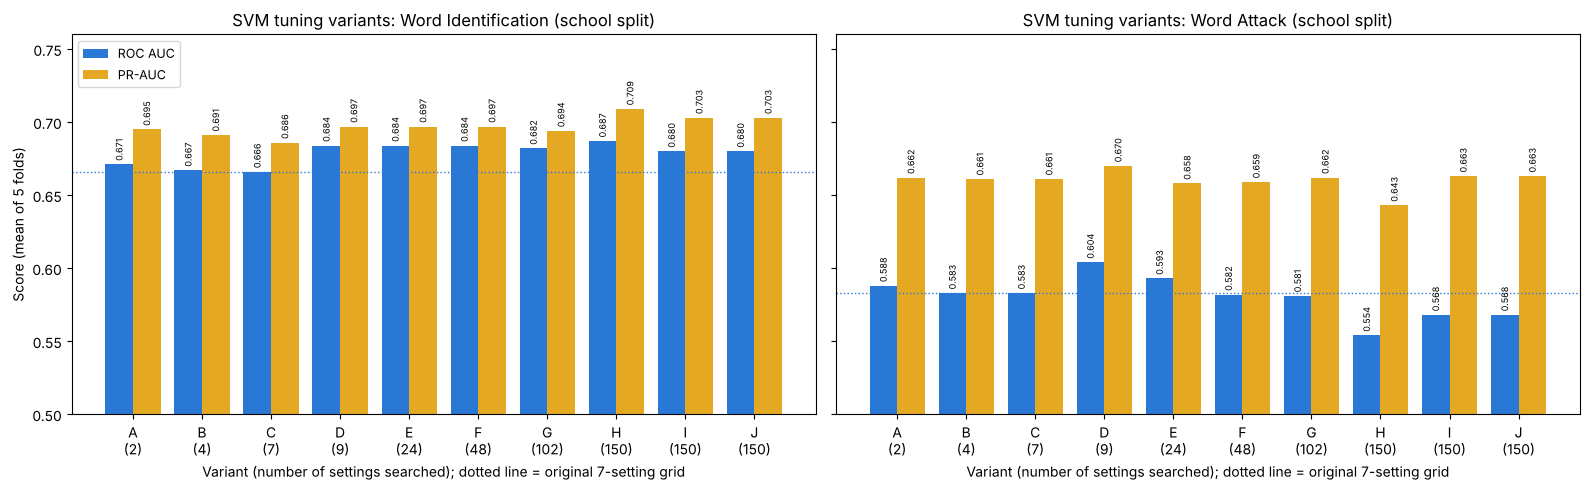

In [7]:
school = summary.loc["school"].reset_index()
labels = [v.split(".")[0] for v in school["variant"].unique()]
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, target_name in zip(axes, TARGETS):
    t = school[school["target"] == target_name]
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["ROC AUC"], width=0.4, color="#2a78d6", label="ROC AUC")
    ax.bar(x + 0.2, t["PR-AUC"], width=0.4, color="#e5a823", label="PR-AUC")
    for xi, (r, p) in enumerate(zip(t["ROC AUC"], t["PR-AUC"])):
        ax.text(xi - 0.2, r + 0.004, f"{r:.3f}", ha="center", fontsize=6.5, rotation=90)
        ax.text(xi + 0.2, p + 0.004, f"{p:.3f}", ha="center", fontsize=6.5, rotation=90)
    ax.axhline(t[t["variant"].str.startswith("C.")]["ROC AUC"].iloc[0], color="#2a78d6", linestyle=":", linewidth=1)
    sizes = ["2", "4", "7", "9", "24", "48", "102", "150", "150", "150"]
    ax.set_xticks(x, [f"{l}\n({n})" for l, n in zip(labels, sizes)])
    ax.set_ylim(0.5, 0.76)
    ax.set_title(f"SVM tuning variants: {target_name} (school split)")
    ax.set_xlabel("Variant (number of settings searched); dotted line = original 7-setting grid")
axes[0].set_ylabel("Score (mean of 5 folds)")
axes[0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS / "svm_tuning_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Settings chosen in each fold (school split)
If the best setting changes a lot from fold to fold, the search is fitting noise rather than finding a better model.

In [8]:
school_picks = settings[settings["split"] == "school"]
for variant in ["E. medium grid (24 settings, now used)", "H. random search (150), pick by ROC AUC"]:
    print(variant)
    display(school_picks[school_picks["variant"] == variant].pivot(index="fold", columns="target", values="setting"))

E. medium grid (24 settings, now used)


target,Word Attack,Word Identification
fold,,
1,"rbf, C=3, gamma=scale, standard scaling","rbf, C=3, gamma=0.01, standard scaling"
2,"linear, C=3, standard scaling","rbf, C=3, gamma=0.01, standard scaling"
3,"rbf, C=10, gamma=0.01, standard scaling","rbf, C=3, gamma=0.01, standard scaling"
4,"rbf, C=0.1, gamma=0.01, standard scaling","rbf, C=1, gamma=0.01, standard scaling"
5,"rbf, C=30, gamma=0.01, standard scaling","rbf, C=10, gamma=0.01, standard scaling"


H. random search (150), pick by ROC AUC


target,Word Attack,Word Identification
fold,,
1,"rbf, C=0.693, gamma=0.398, balanced, robust sc...","rbf, C=1.32, gamma=0.0233, robust scaling"
2,"linear, C=6.49, balanced, robust scaling","linear, C=4.32, quantile scaling"
3,"sigmoid, C=0.108, gamma=0.436, balanced, stand...","rbf, C=12.9, gamma=0.00367, robust scaling"
4,"linear, C=0.555, balanced, robust scaling","rbf, C=1.32, gamma=0.0233, robust scaling"
5,"rbf, C=3.67, gamma=0.0736, balanced, robust sc...","linear, C=4.32, quantile scaling"


## 7. Conclusions
| School split | Settings | Word ID ROC AUC | Word Attack ROC AUC |
|---|---|---|---|
| A. Tiny grid | 2 | 0.671 | 0.588 |
| C. Original grid | 7 | 0.666 | 0.583 |
| D. Small RBF grid | 9 | 0.684 | **0.604** |
| **E. Medium grid (now used)** | **24** | **0.684** | 0.593 |
| F. Medium + class weights | 48 | 0.684 | 0.582 |
| G. Wider grid | 102 | 0.682 | 0.581 |
| H. Random search | 150 | **0.687** | 0.554 |

- **Small grids (2, 4, 7 settings) all score about the same.** They only change C and leave gamma at its default.
- **What helps is trying small gamma values** (a smoother RBF boundary): the 9- and 24-setting grids include them and
  gain about +0.02 ROC AUC for Word ID and +0.01 to +0.02 for Word Attack, on both splits.
- **Bigger searches start to overfit the tuning:** from 48 settings up, Word Attack gets worse (down to 0.554 at 150).
  With many options and only about 34 training schools per fold, the "best" setting partly wins by luck; the folds
  pick very different kernels and values of C.
- **Choosing by PR-AUC or tuning the cutoff does not help.**
- **Decision:** `anupama_svm_cv.ipynb` now uses the **24-setting medium grid**: it covers both kernels and the small
  gamma values, and gives the best overall balance. The 9-setting grid is about as good (within 0.01); choosing it
  now, after seeing these test-fold results, would be picking by the test folds.
- The gains are small compared with the ±0.05 spread between folds: as with the decision tree depth and the t-SNE
  picture, the limit comes from the data, not from the tuning.